In [1]:

# Cell 1: Import libraries and verify dependencies

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

import pydicom
from PIL import Image

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Pydicom:", pydicom.__version__)

print("\nAll core libraries imported successfully!")


NumPy: 2.5.4
Pandas: 3.0.6
Pydicom: 3.0.2

All core libraries imported successfully!


In [2]:

# Cell 2: Project configuration

ROOT = Path.cwd().parent

IMAGE_DIR = ROOT / "data" / "images" / "train" / "vindr_300"
PROCESSED_DIR = ROOT / "data" / "processed"

MANIFEST_PATH = PROCESSED_DIR / "vindr_300_image_manifest.csv"
BBOX_PATH = PROCESSED_DIR / "vindr_300_bounding_boxes.csv"

OUTPUT_IMAGE_DIR = PROCESSED_DIR / "images_256"
OUTPUT_MASK_DIR = PROCESSED_DIR / "masks_256"

OUTPUT_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_MASK_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 256

CLASS_NAMES = [
    "Aortic enlargement",
    "Cardiomegaly",
    "Pleural thickening",
    "Pulmonary fibrosis",
    "Lung Opacity"
]

CLASS_TO_INDEX = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

print("Project root:", ROOT)
print("DICOM directory:", IMAGE_DIR)
print("Output image directory:", OUTPUT_IMAGE_DIR)
print("Output mask directory:", OUTPUT_MASK_DIR)
print("\nClass mapping:", CLASS_TO_INDEX)


Project root: c:\Users\johnm\chest-xray-ai-annotation
DICOM directory: c:\Users\johnm\chest-xray-ai-annotation\data\images\train\vindr_300
Output image directory: c:\Users\johnm\chest-xray-ai-annotation\data\processed\images_256
Output mask directory: c:\Users\johnm\chest-xray-ai-annotation\data\processed\masks_256

Class mapping: {'Aortic enlargement': 0, 'Cardiomegaly': 1, 'Pleural thickening': 2, 'Pulmonary fibrosis': 3, 'Lung Opacity': 4}


In [3]:

# Cell 3: Load manifest and bounding boxes

manifest = pd.read_csv(MANIFEST_PATH)
boxes = pd.read_csv(BBOX_PATH)

print("Manifest shape:", manifest.shape)
print("Bounding-box table shape:", boxes.shape)

print("\nManifest columns:")
print(manifest.columns.tolist())

print("\nBounding-box columns:")
print(boxes.columns.tolist())

print("\nUnique images:", manifest["image_id"].nunique())
print("Bounding-box rows:", len(boxes))

print("\nFinding distribution:")
print(boxes["class_name"].value_counts())


Manifest shape: (300, 13)
Bounding-box table shape: (1799, 7)

Manifest columns:
['image_id', 'sample_order', 'Aortic enlargement', 'Cardiomegaly', 'Pleural thickening', 'Pulmonary fibrosis', 'Lung Opacity', 'number_of_target_findings', 'bbox_count_Aortic enlargement', 'bbox_count_Cardiomegaly', 'bbox_count_Pleural thickening', 'bbox_count_Pulmonary fibrosis', 'bbox_count_Lung Opacity']

Bounding-box columns:
['image_id', 'rad_id', 'class_name', 'x_min', 'y_min', 'x_max', 'y_max']

Unique images: 300
Bounding-box rows: 1799

Finding distribution:
class_name
Aortic enlargement    522
Cardiomegaly          379
Pleural thickening    359
Pulmonary fibrosis    337
Lung Opacity          202
Name: count, dtype: int64


In [4]:

# Cell 4: Verify DICOM availability

dicom_files = list(IMAGE_DIR.glob("*.dicom"))

available_ids = {file.stem for file in dicom_files}
selected_ids = set(manifest["image_id"].astype(str))

missing_ids = selected_ids - available_ids
extra_ids = available_ids - selected_ids

print("Expected images:", len(selected_ids))
print("Found DICOM files:", len(available_ids))
print("Missing images:", len(missing_ids))
print("Unexpected files:", len(extra_ids))

if missing_ids:
    print("\nMissing image IDs:", list(missing_ids)[:10])
else:
    print("\nAll selected images are available!")


Expected images: 300
Found DICOM files: 300
Missing images: 0
Unexpected files: 0

All selected images are available!


In [5]:

# Cell 5: DICOM preprocessing function

def preprocess_dicom(dicom_path, image_size=256):

    ds = pydicom.dcmread(str(dicom_path))

    # Extract pixel array
    image = ds.pixel_array.astype(np.float32)

    # Ensure this is a 2D image
    if image.ndim != 2:
        raise ValueError(
            f"Expected 2D image, got shape {image.shape}: {dicom_path.name}"
        )

    # Apply modality LUT/rescale when available
    slope = float(getattr(ds, "RescaleSlope", 1))
    intercept = float(getattr(ds, "RescaleIntercept", 0))
    image = image * slope + intercept

    # Handle MONOCHROME1
    photometric = getattr(ds, "PhotometricInterpretation", "")
    if photometric == "MONOCHROME1":
        image = image.max() - image

    # Robust intensity normalization
    lower = np.percentile(image, 1)
    upper = np.percentile(image, 99)

    if upper <= lower:
        raise ValueError(f"Invalid intensity range: {dicom_path.name}")

    image = np.clip(image, lower, upper)
    image = (image - lower) / (upper - lower)

    # Resize to 256 x 256
    pil_image = Image.fromarray(image.astype(np.float32))
    pil_image = pil_image.resize(
        (image_size, image_size),
        resample=Image.Resampling.BILINEAR
    )

    image = np.asarray(pil_image, dtype=np.float32)

    return image, ds


Image ID: 690a74b4ebf969fbadc5ad0a1187968d
Original dimensions: 2712 x 2626
Photometric interpretation: MONOCHROME2
Processed shape: (256, 256)
Minimum intensity: 0.0
Maximum intensity: 0.9934912
Data type: float32


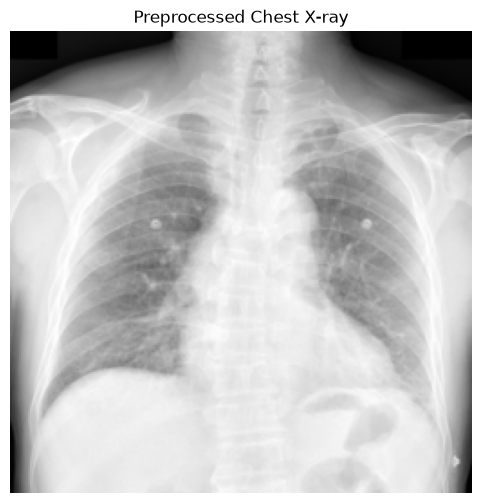

In [6]:

# Cell 6: Test one DICOM image

sample_id = manifest.iloc[0]["image_id"]
sample_path = IMAGE_DIR / f"{sample_id}.dicom"

sample_image, sample_ds = preprocess_dicom(sample_path)

print("Image ID:", sample_id)
print("Original dimensions:", sample_ds.Rows, "x", sample_ds.Columns)
print("Photometric interpretation:",
      sample_ds.PhotometricInterpretation)

print("Processed shape:", sample_image.shape)
print("Minimum intensity:", sample_image.min())
print("Maximum intensity:", sample_image.max())
print("Data type:", sample_image.dtype)

plt.figure(figsize=(6, 6))
plt.imshow(sample_image, cmap="gray")
plt.title("Preprocessed Chest X-ray")
plt.axis("off")
plt.show()


In [7]:

# Cell 7: Bounding-box coordinate transformation

def transform_bbox(row, original_width, original_height,
                    image_size=256):

    scale_x = image_size / original_width
    scale_y = image_size / original_height

    x_min = int(np.floor(row["x_min"] * scale_x))
    y_min = int(np.floor(row["y_min"] * scale_y))

    x_max = int(np.ceil(row["x_max"] * scale_x))
    y_max = int(np.ceil(row["y_max"] * scale_y))

    # Clip coordinates to image boundaries
    x_min = np.clip(x_min, 0, image_size - 1)
    y_min = np.clip(y_min, 0, image_size - 1)

    x_max = np.clip(x_max, 0, image_size)
    y_max = np.clip(y_max, 0, image_size)

    return x_min, y_min, x_max, y_max


In [8]:

# Cell 8: Inspect transformed bounding boxes

sample_boxes = boxes[
    boxes["image_id"] == sample_id
].copy()

print("Original bounding boxes:", len(sample_boxes))

transformed_boxes = []

for _, row in sample_boxes.iterrows():

    x0, y0, x1, y1 = transform_bbox(
        row,
        original_width=sample_ds.Columns,
        original_height=sample_ds.Rows
    )

    transformed_boxes.append({
        "class_name": row["class_name"],
        "rad_id": row["rad_id"],
        "x_min_256": x0,
        "y_min_256": y0,
        "x_max_256": x1,
        "y_max_256": y1
    })

transformed_df = pd.DataFrame(transformed_boxes)

display(transformed_df.head(10))

print("\nTransformed box count:", len(transformed_df))


Original bounding boxes: 10


,class_name,rad_id,x_min_256,y_min_256,x_max_256,y_max_256
0,Aortic enlargement,R10,136,87,173,121
1,Aortic enlargement,R8,137,88,172,129
2,Aortic enlargement,R9,135,86,173,125
3,Cardiomegaly,R10,92,167,215,205
4,Cardiomegaly,R8,92,156,213,200
5,Cardiomegaly,R9,91,168,217,206
6,Pleural thickening,R10,152,42,197,65
7,Pleural thickening,R8,155,44,197,56
8,Pleural thickening,R9,155,46,196,58
9,Pulmonary fibrosis,R9,172,116,208,137



Transformed box count: 10


In [9]:

# Cell 9: Generate five-channel mask for one sample

sample_mask = np.zeros(
    (IMAGE_SIZE, IMAGE_SIZE, len(CLASS_NAMES)),
    dtype=np.uint8
)

for _, row in sample_boxes.iterrows():

    class_name = row["class_name"]
    channel = CLASS_TO_INDEX[class_name]

    x0, y0, x1, y1 = transform_bbox(
        row,
        original_width=sample_ds.Columns,
        original_height=sample_ds.Rows
    )

    # Union of all radiologists' boxes for this finding
    sample_mask[y0:y1, x0:x1, channel] = 1

print("Mask shape:", sample_mask.shape)
print("Mask data type:", sample_mask.dtype)

for class_name, channel in CLASS_TO_INDEX.items():

    positive_pixels = int(sample_mask[:, :, channel].sum())

    print(
        f"{class_name}: "
        f"{positive_pixels} positive pixels"
    )


Mask shape: (256, 256, 5)
Mask data type: uint8
Aortic enlargement: 1622 positive pixels
Cardiomegaly: 6242 positive pixels
Pleural thickening: 1035 positive pixels
Pulmonary fibrosis: 756 positive pixels
Lung Opacity: 0 positive pixels


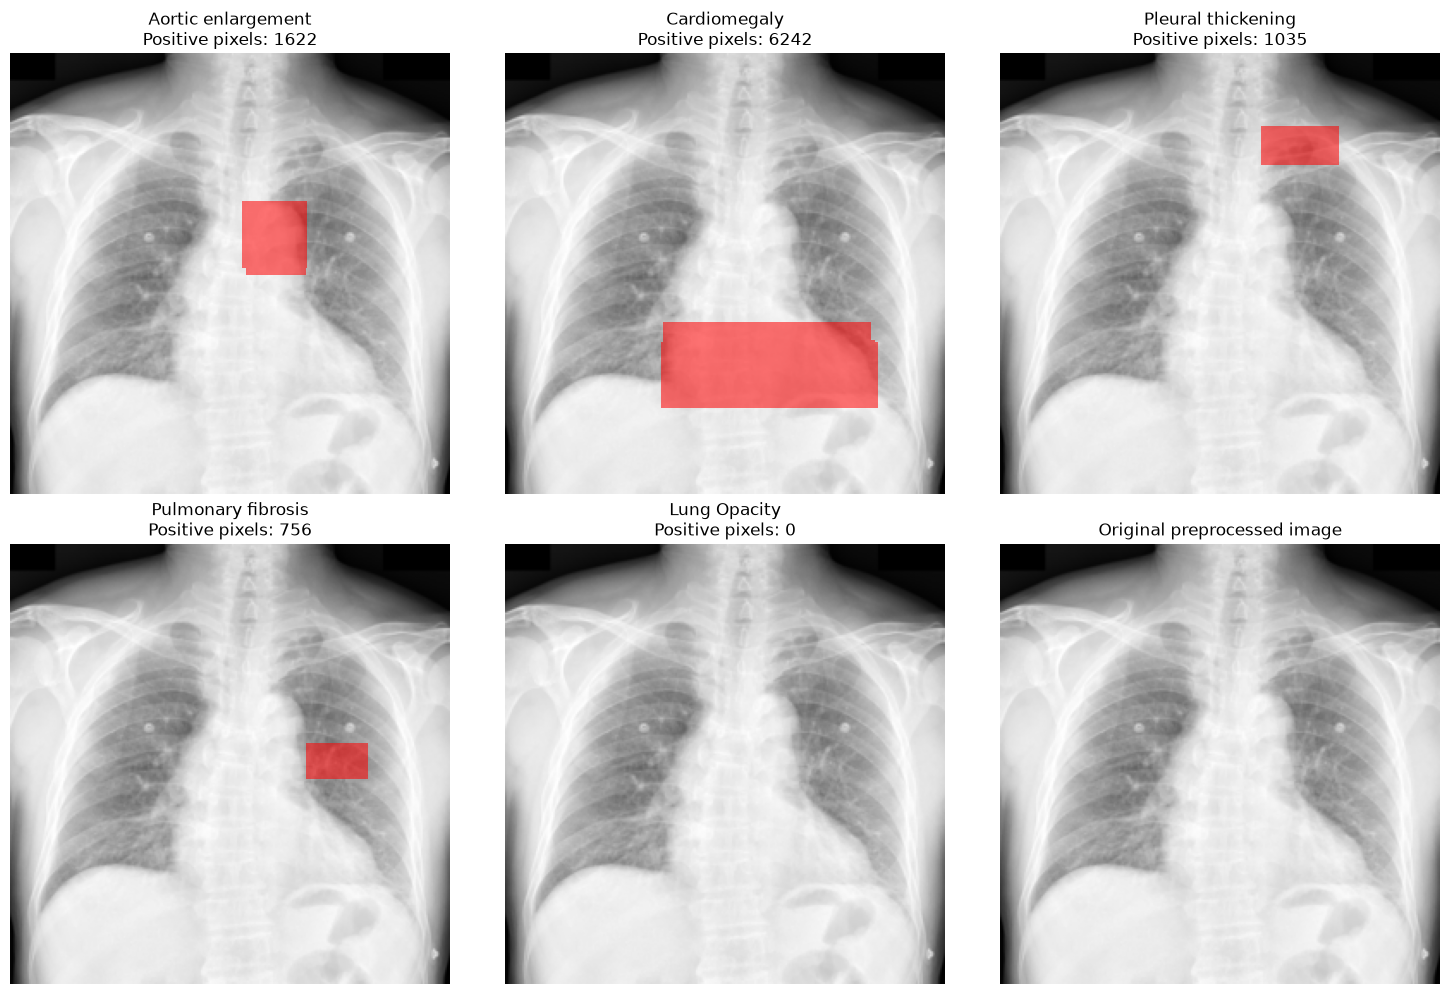

In [10]:

# Cell 10: Visualize each mask channel

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes = axes.flatten()

for class_name, channel in CLASS_TO_INDEX.items():

    axes[channel].imshow(sample_image, cmap="gray")

    mask_channel = sample_mask[:, :, channel]

    axes[channel].imshow(
        np.ma.masked_where(
            mask_channel == 0,
            mask_channel
        ),
        cmap="autumn",
        alpha=0.55,
        interpolation="nearest"
    )

    axes[channel].set_title(
        f"{class_name}\n"
        f"Positive pixels: {mask_channel.sum()}"
    )

    axes[channel].axis("off")

# Show original image in the sixth panel
axes[5].imshow(sample_image, cmap="gray")
axes[5].set_title("Original preprocessed image")
axes[5].axis("off")

plt.tight_layout()
plt.show()


In [11]:

# Cell 11: Verify sample image labels and annotations

sample_labels = manifest[
    manifest["image_id"] == sample_id
]

print("Image ID:", sample_id)

print("\nImage-level labels:")
display(
    sample_labels[
        ["Aortic enlargement",
         "Cardiomegaly",
         "Pleural thickening",
         "Pulmonary fibrosis",
         "Lung Opacity"]
    ]
)

print("\nBounding-box classes:")
print(sample_boxes["class_name"].value_counts())


Image ID: 690a74b4ebf969fbadc5ad0a1187968d

Image-level labels:


,Aortic enlargement,Cardiomegaly,Pleural thickening,Pulmonary fibrosis,Lung Opacity
0,1,1,1,1,0



Bounding-box classes:
class_name
Aortic enlargement    3
Cardiomegaly          3
Pleural thickening    3
Pulmonary fibrosis    1
Name: count, dtype: int64


In [12]:

# Cell 12: Generate and save all 300 image-mask pairs

processing_results = []
processing_errors = []

# Group bounding boxes by image for faster lookup
bbox_groups = {
    image_id: group.copy()
    for image_id, group in boxes.groupby("image_id")
}

for index, row in manifest.iterrows():

    image_id = str(row["image_id"])

    dicom_path = IMAGE_DIR / f"{image_id}.dicom"

    try:
        # 1. Preprocess DICOM
        image, ds = preprocess_dicom(dicom_path)

        # 2. Create five-channel mask
        mask = np.zeros(
            (IMAGE_SIZE, IMAGE_SIZE, len(CLASS_NAMES)),
            dtype=np.uint8
        )

        image_boxes = bbox_groups.get(
            image_id,
            pd.DataFrame()
        )

        # 3. Generate masks from all radiologist boxes
        for _, bbox in image_boxes.iterrows():

            class_name = bbox["class_name"]

            if class_name not in CLASS_TO_INDEX:
                continue

            channel = CLASS_TO_INDEX[class_name]

            x0, y0, x1, y1 = transform_bbox(
                bbox,
                original_width=ds.Columns,
                original_height=ds.Rows
            )

            if x1 > x0 and y1 > y0:
                mask[y0:y1, x0:x1, channel] = 1

        # 4. Save processed image and mask
        np.save(
            OUTPUT_IMAGE_DIR / f"{image_id}.npy",
            image.astype(np.float32)
        )

        np.save(
            OUTPUT_MASK_DIR / f"{image_id}.npy",
            mask.astype(np.uint8)
        )

        # 5. Record statistics
        result = {
            "image_id": image_id,
            "image_shape": str(image.shape),
            "mask_shape": str(mask.shape),
            "bbox_count": len(image_boxes)
        }

        for class_name, channel in CLASS_TO_INDEX.items():

            result[f"pixels_{class_name}"] = int(
                mask[:, :, channel].sum()
            )

        processing_results.append(result)

        if (len(processing_results) % 25 == 0):
            print(
                f"Processed "
                f"{len(processing_results)}/{len(manifest)} images"
            )

    except Exception as error:

        processing_errors.append({
            "image_id": image_id,
            "error": str(error)
        })

print("\nPROCESSING COMPLETE")
print("Successful:", len(processing_results))
print("Failed:", len(processing_errors))


Processed 25/300 images
Processed 50/300 images
Processed 75/300 images
Processed 100/300 images
Processed 125/300 images
Processed 150/300 images
Processed 175/300 images
Processed 200/300 images
Processed 225/300 images
Processed 250/300 images
Processed 275/300 images
Processed 300/300 images

PROCESSING COMPLETE
Successful: 300
Failed: 0


In [13]:

# Cell 13: Save preprocessing and mask-generation report

processing_df = pd.DataFrame(processing_results)

processing_report_path = (
    PROCESSED_DIR / "vindr_300_mask_generation_report.csv"
)

processing_df.to_csv(
    processing_report_path,
    index=False
)

# Save errors separately, if any
if processing_errors:

    errors_df = pd.DataFrame(processing_errors)

    errors_path = (
        PROCESSED_DIR / "mask_generation_errors.csv"
    )

    errors_df.to_csv(errors_path, index=False)

    print("Error report saved:", errors_path)

print("=" * 50)
print("MASK GENERATION SUMMARY")
print("=" * 50)

print("Successful images:", len(processing_df))
print("Failed images:", len(processing_errors))

print("\nTotal positive pixels per finding:")

for class_name in CLASS_NAMES:

    column = f"pixels_{class_name}"

    total_pixels = processing_df[column].sum()

    print(f"{class_name}: {total_pixels:,}")

print("\nReport saved:", processing_report_path)


MASK GENERATION SUMMARY
Successful images: 300
Failed images: 0

Total positive pixels per finding:
Aortic enlargement: 279,825
Cardiomegaly: 795,245
Pleural thickening: 154,131
Pulmonary fibrosis: 288,035
Lung Opacity: 403,962

Report saved: c:\Users\johnm\chest-xray-ai-annotation\data\processed\vindr_300_mask_generation_report.csv


In [14]:

# Cell 14: Validate saved image-mask pairs

saved_images = list(OUTPUT_IMAGE_DIR.glob("*.npy"))
saved_masks = list(OUTPUT_MASK_DIR.glob("*.npy"))

print("=" * 50)
print("SAVED ARRAY VALIDATION")
print("=" * 50)

print("Saved images:", len(saved_images))
print("Saved masks:", len(saved_masks))

# Check matching image-mask IDs
image_ids = {f.stem for f in saved_images}
mask_ids = {f.stem for f in saved_masks}

print("\nImages without masks:", len(image_ids - mask_ids))
print("Masks without images:", len(mask_ids - image_ids))

# Validate every saved pair
validation_errors = []

for image_id in sorted(image_ids & mask_ids):

    try:
        image = np.load(OUTPUT_IMAGE_DIR / f"{image_id}.npy")
        mask = np.load(OUTPUT_MASK_DIR / f"{image_id}.npy")

        if image.shape != (IMAGE_SIZE, IMAGE_SIZE):
            raise ValueError(f"Invalid image shape: {image.shape}")

        if mask.shape != (
            IMAGE_SIZE, IMAGE_SIZE, len(CLASS_NAMES)
        ):
            raise ValueError(f"Invalid mask shape: {mask.shape}")

        if image.dtype != np.float32:
            raise ValueError(f"Invalid image dtype: {image.dtype}")

        if mask.dtype != np.uint8:
            raise ValueError(f"Invalid mask dtype: {mask.dtype}")

        if not np.isfinite(image).all():
            raise ValueError("Image contains NaN or infinite values")

        if not set(np.unique(mask)).issubset({0, 1}):
            raise ValueError(
                f"Unexpected mask values: {np.unique(mask)}"
            )

    except Exception as error:

        validation_errors.append({
            "image_id": image_id,
            "error": str(error)
        })

print("\nPairs validated:", len(image_ids & mask_ids))
print("Validation failures:", len(validation_errors))

if validation_errors:
    display(pd.DataFrame(validation_errors))

# Inspect one example pair
if image_ids & mask_ids:

    test_id = sorted(image_ids & mask_ids)[0]

    test_image = np.load(
        OUTPUT_IMAGE_DIR / f"{test_id}.npy"
    )

    test_mask = np.load(
        OUTPUT_MASK_DIR / f"{test_id}.npy"
    )

    print("\nSample image ID:", test_id)
    print("Image shape:", test_image.shape)
    print("Image dtype:", test_image.dtype)
    print("Image intensity range:",
          test_image.min(), "to", test_image.max())

    print("\nMask shape:", test_mask.shape)
    print("Mask dtype:", test_mask.dtype)
    print("Mask unique values:", np.unique(test_mask))

# Final validation status
if (
    len(saved_images) == 300
    and len(saved_masks) == 300
    and image_ids == mask_ids
    and len(validation_errors) == 0
):
    print("\nSUCCESS: All 300 image-mask pairs passed validation!")
else:
    print("\nWARNING: Dataset validation needs attention.")


SAVED ARRAY VALIDATION
Saved images: 300
Saved masks: 300

Images without masks: 0
Masks without images: 0

Pairs validated: 300
Validation failures: 0

Sample image ID: 020717d6ab0b440b37978d9bace9f9b2
Image shape: (256, 256)
Image dtype: float32
Image intensity range: 0.0 to 1.0

Mask shape: (256, 256, 5)
Mask dtype: uint8
Mask unique values: [0 1]

SUCCESS: All 300 image-mask pairs passed validation!


In [1]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFiles and folders here:")

for item in Path.cwd().iterdir():
    print(item.name)

Current working directory:
c:\Users\johnm\chest-xray-ai-annotation\notebooks

Files and folders here:
02_mask_generation.ipynb
03_dataset_splitting.ipynb
04_unet_training.ipynb
dataset_inspection.ipynb


In [2]:
from pathlib import Path

PROJECT = Path(r"C:\Users\johnm\chest-xray-ai-annotation")

print("Searching project:", PROJECT)

for notebook in PROJECT.rglob("*.ipynb"):
    print(notebook)

Searching project: C:\Users\johnm\chest-xray-ai-annotation
C:\Users\johnm\chest-xray-ai-annotation\notebooks\02_mask_generation.ipynb
C:\Users\johnm\chest-xray-ai-annotation\notebooks\03_dataset_splitting.ipynb
C:\Users\johnm\chest-xray-ai-annotation\notebooks\04_unet_training.ipynb
C:\Users\johnm\chest-xray-ai-annotation\notebooks\dataset_inspection.ipynb


In [3]:
notebook_path = Path("02_mask_generation.ipynb")

In [4]:
import json
from pathlib import Path

notebook_path = Path("02_mask_generation.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "pixel_array",
    "MONOCHROME1",
    "MONOCHROME2",
    "pydicom",
    "percentile",
    "normalize",
    "normalization",
    "resize",
    "cv2",
    "np.save",
    "float32",
    "255.0",
    "256"
]

for i, cell in enumerate(notebook["cells"]):

    if cell["cell_type"] not in ["code", "markdown"]:
        continue

    source = "".join(cell["source"])

    if any(k.lower() in source.lower() for k in keywords):

        print(f"\n{'='*70}")
        print(f"CELL {i} | {cell['cell_type'].upper()}")
        print('='*70)
        print(source[:12000])


CELL 0 | CODE

# Cell 1: Import libraries and verify dependencies

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

import pydicom
from PIL import Image

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Pydicom:", pydicom.__version__)

print("\nAll core libraries imported successfully!")


CELL 1 | CODE

# Cell 2: Project configuration

ROOT = Path.cwd().parent

IMAGE_DIR = ROOT / "data" / "images" / "train" / "vindr_300"
PROCESSED_DIR = ROOT / "data" / "processed"

MANIFEST_PATH = PROCESSED_DIR / "vindr_300_image_manifest.csv"
BBOX_PATH = PROCESSED_DIR / "vindr_300_bounding_boxes.csv"

OUTPUT_IMAGE_DIR = PROCESSED_DIR / "images_256"
OUTPUT_MASK_DIR = PROCESSED_DIR / "masks_256"

OUTPUT_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_MASK_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 256

CLASS_NAMES = [
    "Aortic enlargement",
    "Cardiomegaly",
    "Pleural

In [5]:
import json
from pathlib import Path

notebook_path = Path("02_mask_generation.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "pixel_array",
    "MONOCHROME1",
    "MONOCHROME2",
    "pydicom.dcmread",
    "dcmread",
    "Image.fromarray",
    "Image.resize",
    "resize(",
    "np.save",
    "astype(np.float32)",
    "astype('float32')",
    "normalize",
    "clip(",
    "percentile"
]

for i, cell in enumerate(notebook["cells"]):

    source = "".join(cell.get("source", []))

    matching_lines = [
        (line_number, line)
        for line_number, line in enumerate(source.splitlines(), 1)
        if any(keyword.lower() in line.lower() for keyword in keywords)
    ]

    if matching_lines:
        print(f"\n{'='*65}")
        print(f"CELL {i}")
        print('='*65)

        lines = source.splitlines()

        # Print matching lines with surrounding context
        selected = set()

        for line_number, _ in matching_lines:
            selected.update(
                range(
                    max(1, line_number - 5),
                    min(len(lines), line_number + 5) + 1
                )
            )

        for line_number in sorted(selected):
            print(f"{line_number:03}: {lines[line_number - 1]}")


CELL 4
001: 
002: # Cell 5: DICOM preprocessing function
003: 
004: def preprocess_dicom(dicom_path, image_size=256):
005: 
006:     ds = pydicom.dcmread(str(dicom_path))
007: 
008:     # Extract pixel array
009:     image = ds.pixel_array.astype(np.float32)
010: 
011:     # Ensure this is a 2D image
012:     if image.ndim != 2:
013:         raise ValueError(
014:             f"Expected 2D image, got shape {image.shape}: {dicom_path.name}"
017:     # Apply modality LUT/rescale when available
018:     slope = float(getattr(ds, "RescaleSlope", 1))
019:     intercept = float(getattr(ds, "RescaleIntercept", 0))
020:     image = image * slope + intercept
021: 
022:     # Handle MONOCHROME1
023:     photometric = getattr(ds, "PhotometricInterpretation", "")
024:     if photometric == "MONOCHROME1":
025:         image = image.max() - image
026: 
027:     # Robust intensity normalization
028:     lower = np.percentile(image, 1)
029:     upper = np.percentile(image, 99)
030: 
031:     if upper

In [6]:
import json
from pathlib import Path

notebook_path = Path("02_mask_generation.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

# Cell 4 contains the original preprocessing function
source = "".join(notebook["cells"][4]["source"])

print(source)


# Cell 5: DICOM preprocessing function

def preprocess_dicom(dicom_path, image_size=256):

    ds = pydicom.dcmread(str(dicom_path))

    # Extract pixel array
    image = ds.pixel_array.astype(np.float32)

    # Ensure this is a 2D image
    if image.ndim != 2:
        raise ValueError(
            f"Expected 2D image, got shape {image.shape}: {dicom_path.name}"
        )

    # Apply modality LUT/rescale when available
    slope = float(getattr(ds, "RescaleSlope", 1))
    intercept = float(getattr(ds, "RescaleIntercept", 0))
    image = image * slope + intercept

    # Handle MONOCHROME1
    photometric = getattr(ds, "PhotometricInterpretation", "")
    if photometric == "MONOCHROME1":
        image = image.max() - image

    # Robust intensity normalization
    lower = np.percentile(image, 1)
    upper = np.percentile(image, 99)

    if upper <= lower:
        raise ValueError(f"Invalid intensity range: {dicom_path.name}")

    image = np.clip(image, lower, upper)
    image = (imag

In [7]:
import json
from pathlib import Path

notebook_path = Path("02_mask_generation.ipynb")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

source = "".join(notebook["cells"][4]["source"])

# Save the complete function separately
output_path = Path("preprocessing_function.txt")
output_path.write_text(source, encoding="utf-8")

print("Function extracted successfully!")
print("Saved at:", output_path.resolve())
print("Total lines:", len(source.splitlines()))

# Print numbered lines in smaller chunks
for start in range(0, len(source.splitlines()), 20):
    lines = source.splitlines()[start:start+20]

    print(f"\n--- LINES {start+1}-{start+len(lines)} ---")

    for number, line in enumerate(lines, start+1):
        print(f"{number:03}: {line}")

Function extracted successfully!
Saved at: C:\Users\johnm\chest-xray-ai-annotation\notebooks\preprocessing_function.txt
Total lines: 46

--- LINES 1-20 ---
001: 
002: # Cell 5: DICOM preprocessing function
003: 
004: def preprocess_dicom(dicom_path, image_size=256):
005: 
006:     ds = pydicom.dcmread(str(dicom_path))
007: 
008:     # Extract pixel array
009:     image = ds.pixel_array.astype(np.float32)
010: 
011:     # Ensure this is a 2D image
012:     if image.ndim != 2:
013:         raise ValueError(
014:             f"Expected 2D image, got shape {image.shape}: {dicom_path.name}"
015:         )
016: 
017:     # Apply modality LUT/rescale when available
018:     slope = float(getattr(ds, "RescaleSlope", 1))
019:     intercept = float(getattr(ds, "RescaleIntercept", 0))
020:     image = image * slope + intercept

--- LINES 21-40 ---
021: 
022:     # Handle MONOCHROME1
023:     photometric = getattr(ds, "PhotometricInterpretation", "")
024:     if photometric == "MONOCHROME1":
025: 

In [ ]:
from pathlib import Path

path = Path("preprocessing_function.txt")

lines = path.read_text(encoding="utf-8").splitlines()

for i in range(16, len(lines)):
    print(f"{i+1:03}: {lines[i]}")

017:     # Apply modality LUT/rescale when available
018:     slope = float(getattr(ds, "RescaleSlope", 1))
019:     intercept = float(getattr(ds, "RescaleIntercept", 0))
020:     image = image * slope + intercept
021: 
022:     # Handle MONOCHROME1
023:     photometric = getattr(ds, "PhotometricInterpretation", "")
024:     if photometric == "MONOCHROME1":
025:         image = image.max() - image
026: 
027:     # Robust intensity normalization
028:     lower = np.percentile(image, 1)
029:     upper = np.percentile(image, 99)
030: 
031:     if upper <= lower:
032:         raise ValueError(f"Invalid intensity range: {dicom_path.name}")
033: 
034:     image = np.clip(image, lower, upper)
035:     image = (image - lower) / (upper - lower)
036: 
037:     # Resize to 256 x 256
038:     pil_image = Image.fromarray(image.astype(np.float32))
039:     pil_image = pil_image.resize(
040:         (image_size, image_size),
041:         resample=Image.Resampling.BILINEAR
042:     )
043: 
044:     im

: 